In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv('../dataset/dataset_bai03.csv')


In [2]:
df.replace(to_replace="?", value=np.nan, inplace=True)

,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,3,NaN,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495
1,3,NaN,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500
2,1,NaN,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500
3,2,164,audi,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950
4,2,164,audi,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
200,-1,95,volvo,gas,std,four,sedan,rwd,front,109.1,...,141,mpfi,3.78,3.15,9.5,114,5400,23,28,16845
201,-1,95,volvo,gas,turbo,four,sedan,rwd,front,109.1,...,141,mpfi,3.78,3.15,8.7,160,5300,19,25,19045
202,-1,95,volvo,gas,std,four,sedan,rwd,front,109.1,...,173,mpfi,3.58,2.87,8.8,134,5500,18,23,21485
203,-1,95,volvo,diesel,turbo,four,sedan,rwd,front,109.1,...,145,idi,3.01,3.40,23.0,106,4800,26,27,22470


In [3]:
df.dropna(inplace=True)


In [4]:
df

,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
3,2,164,audi,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950
4,2,164,audi,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450
6,1,158,audi,gas,std,four,sedan,fwd,front,105.8,...,136,mpfi,3.19,3.40,8.5,110,5500,19,25,17710
8,1,158,audi,gas,turbo,four,sedan,fwd,front,105.8,...,131,mpfi,3.13,3.40,8.3,140,5500,17,20,23875
10,2,192,bmw,gas,std,two,sedan,rwd,front,101.2,...,108,mpfi,3.50,2.80,8.8,101,5800,23,29,16430
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
200,-1,95,volvo,gas,std,four,sedan,rwd,front,109.1,...,141,mpfi,3.78,3.15,9.5,114,5400,23,28,16845
201,-1,95,volvo,gas,turbo,four,sedan,rwd,front,109.1,...,141,mpfi,3.78,3.15,8.7,160,5300,19,25,19045
202,-1,95,volvo,gas,std,four,sedan,rwd,front,109.1,...,173,mpfi,3.58,2.87,8.8,134,5500,18,23,21485
203,-1,95,volvo,diesel,turbo,four,sedan,rwd,front,109.1,...,145,idi,3.01,3.40,23.0,106,4800,26,27,22470


In [5]:
df['price'].dtype

<StringDtype(storage='python', na_value=nan)>

In [9]:
df['price']=df['price'].astype(float)


In [10]:
bin= np.linspace(min(df['price']), max(df['price']), 4)


In [11]:
pd.cut(df['price'],bins=bin, labels=['T', 'V', 'C'], include_lowest=True)

3      T
4      V
6      V
8      V
10     V
      ..
200    V
201    V
202    V
203    V
204    V
Name: price, Length: 159, dtype: category
Categories (3, str): ['T' < 'V' < 'C']

In [12]:
df['price_bin']=pd.cut(df['price'],bins=bin, labels=['T', 'V', 'C'], include_lowest=True)

In [13]:
df1=pd.get_dummies(df['fuel-type'])


In [14]:
df3=pd.concat([df,df1], axis=1)
df3


,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,...,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price,price_bin,diesel,gas
3,2,164,audi,gas,std,four,sedan,fwd,front,99.8,...,3.40,10.0,102,5500,24,30,13950.0,T,False,True
4,2,164,audi,gas,std,four,sedan,4wd,front,99.4,...,3.40,8.0,115,5500,18,22,17450.0,V,False,True
6,1,158,audi,gas,std,four,sedan,fwd,front,105.8,...,3.40,8.5,110,5500,19,25,17710.0,V,False,True
8,1,158,audi,gas,turbo,four,sedan,fwd,front,105.8,...,3.40,8.3,140,5500,17,20,23875.0,V,False,True
10,2,192,bmw,gas,std,two,sedan,rwd,front,101.2,...,2.80,8.8,101,5800,23,29,16430.0,V,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
200,-1,95,volvo,gas,std,four,sedan,rwd,front,109.1,...,3.15,9.5,114,5400,23,28,16845.0,V,False,True
201,-1,95,volvo,gas,turbo,four,sedan,rwd,front,109.1,...,3.15,8.7,160,5300,19,25,19045.0,V,False,True
202,-1,95,volvo,gas,std,four,sedan,rwd,front,109.1,...,2.87,8.8,134,5500,18,23,21485.0,V,False,True
203,-1,95,volvo,diesel,turbo,four,sedan,rwd,front,109.1,...,3.40,23.0,106,4800,26,27,22470.0,V,True,False


In [15]:
s = pd.Series(data=[2, 5, 8, 1, 3], index=['a', 'b', 'c', 'd', 'e'])


In [24]:
import matplotlib.pyplot as plt

<Axes: >

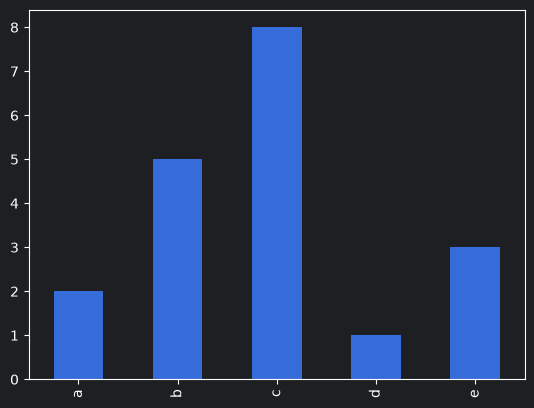

In [25]:
s.plot(kind='bar')

<Axes: >

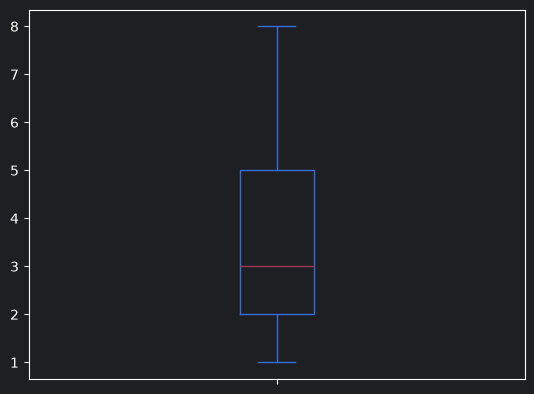

In [17]:
s.plot(kind='box')

<Axes: >

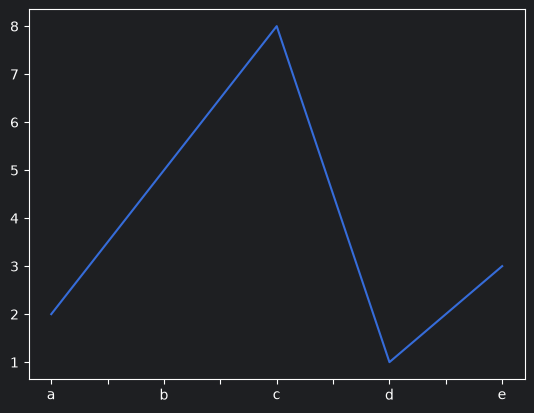

In [26]:
s.plot(kind='line')

In [30]:
df= pd.DataFrame(data={
    'a':[1,2,3, 4],
    'b':[5,6,7,8],
    'c':[9,10, 11, 12] }
)
df

,a,b,c
0,1,5,9
1,2,6,10
2,3,7,11
3,4,8,12


<Axes: >

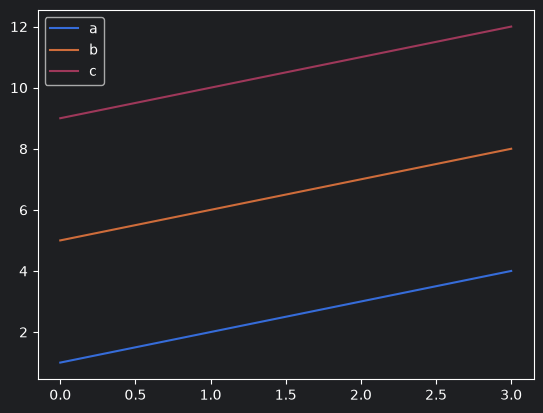

In [20]:
df.plot()

<Axes: xlabel='a'>

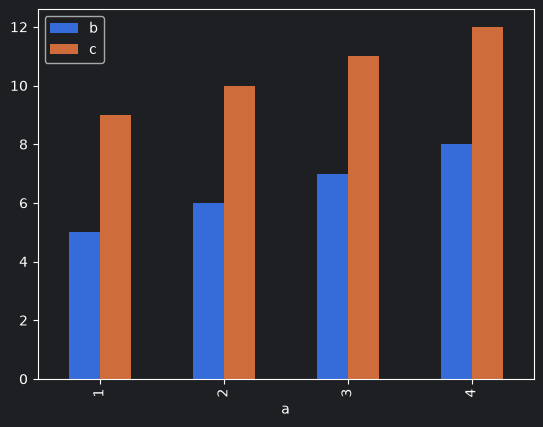

In [28]:
df.plot(kind='bar')

In [31]:
df.set_index('a', inplace=True)

<Axes: xlabel='a'>

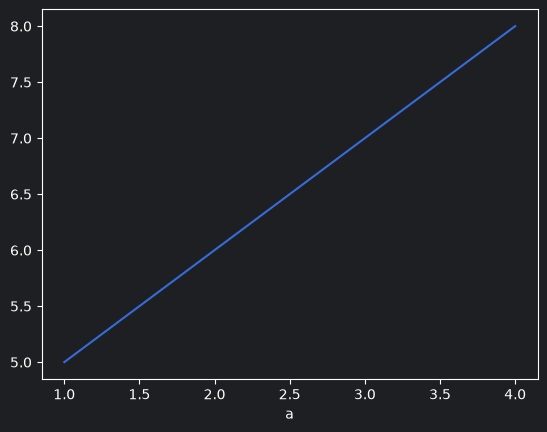

In [32]:
df['b'].plot()